# 08B.2 — Football transfer benchmark

**Objective O3 — prospective transfer.** Does pre-draft Combine tracking improve out-of-sample prediction of an approved NFL football outcome beyond official Combine testing?

**Primary hypothesis (recorded in the registry before any NFL outcome was related to a Combine value):** one pre-selected interpretable tracking family — engineered speed development, model `M2` — against official testing `M1`. Secondary: TCN-B (`M5`) against `M1`. The primary is not the most sophisticated representation on purpose.

| Model | Predictors |
|---|---|
| M0 | position, draft cohort, pre-draft body measurements |
| M1 | M0 + official Combine tests |
| M2 | M1 + engineered speed development |
| M3 | M1 + tracked speed (SPEED2) |
| M4 | M1 + FPCA scores |
| M5 | M1 + TCN-B (8-d) |
| M6 | M1 + untrained encoder (control) |

**Design.** Unit = athlete. The cohort is the Milestone 06 paired cohort restricted to the athletes supporting the outcome (about 90 receivers for separation — *not* the old n = 284). Folds, inner folds and fold-fitted representations are those of Milestone 06: all Combine attempts and all NFL games of an athlete stay in one fold, no encoder is trained here, and no NFL outcome ever touched a Combine representation. Small ridge models, five penalties, inner athlete-grouped tuning. No deep network is trained to predict the outcome.

**Gates.** The notebook refuses to run unless (A) the 08B.0 registry branch is *frozen* or *exploratory* and (B) Gate B of the primary target is PASS. The experiment can pass Gate C with a null result.

**Prerequisites (same `RUN_MODE`).** 00, 02, 04A, 05B, 06A, 06B, 06C, 08B.0, 08B.1. No PyTorch.

In [1]:
RUN_MODE = 'full'             # 'smoke' | 'full'
SEED = 20261011
FORCE_REBUILD = False         # True = recompute the cached stages and RESTART the permutation checkpoint of this configuration
SAVE_TABLES = True
SAVE_FIGURES = True
NUM_WORKERS = 0
EXPERIMENT_VERSION = '08B2.1'
REGISTRY_VERSION = 'v1'
BOOTSTRAP_ITERATIONS = 2000   # paired athlete bootstrap
PERMUTATIONS_PRIMARY = 500    # refits of the ONE primary comparison (linkage null)
PERMUTATIONS_SECONDARY = 200  # refits of each declared secondary comparison and of the outcome-permutation leak check
PROGRESS_INTERVAL = 10        # permutations between progress lines and checkpoint writes
RESUME_MODE = 'resume'        # 'resume' | 'restart' | 'require_complete'
MAX_SECONDS = None            # stop each permutation run cleanly after this many seconds (checkpoint kept); None = run to the end
RUN_SECONDARY_TARGETS = True  # also evaluate approved secondary outcomes (each on its own cohort; never pooled)
SHOW_TABLES = True

In [2]:
from nflbdb.data.config import Phase01Config, configure_runtime

cfg = Phase01Config.load()
configure_runtime(cfg)

from dataclasses import replace

import numpy as np
import polars as pl
from IPython.display import Markdown, display

from nflbdb.data.utils import utc_now
from nflbdb.research.advanced_movement import atlas as at
from nflbdb.research.advanced_movement import checkpoint as ck
from nflbdb.research.advanced_movement import config as amc
from nflbdb.research.advanced_movement import context_outcomes as co
from nflbdb.research.advanced_movement import data as amd
from nflbdb.research.advanced_movement import football_figures as ff
from nflbdb.research.advanced_movement import football_registry as fr
from nflbdb.research.advanced_movement import football_reliability as frl
from nflbdb.research.advanced_movement import football_transfer as ft
from nflbdb.research.advanced_movement import football_validation as fv
from nflbdb.research.advanced_movement import opportunity_validation as ov
from nflbdb.research.advanced_movement import transfer as tr
from nflbdb.research.advanced_movement import transfer_models as tm
from nflbdb.research.advanced_movement import transfer_robust as tx
from nflbdb.research.advanced_movement.artifacts import FootballStore

controls = amc.NotebookControls(run_mode=RUN_MODE, force_rebuild=FORCE_REBUILD, save_figures=SAVE_FIGURES, save_tables=SAVE_TABLES,
                                seed=SEED, num_workers=NUM_WORKERS).validate()
acfg = amc.AdvancedConfig().for_mode(controls)
ftc = ft.FootballTransferConfig().for_mode(controls)
if not controls.smoke:
    ftc = replace(ftc, n_boot=BOOTSTRAP_ITERATIONS, n_perm_primary=PERMUTATIONS_PRIMARY, n_perm_secondary=PERMUTATIONS_SECONDARY, progress_every=PROGRESS_INTERVAL)
tc = ftc.transfer_config(tr.TransferConfig().for_mode(controls))
store = FootballStore(cfg, controls)
up, T = store.upstream, store.transfer
amc.seed_everything(controls.seed)
NB = {'00': '00_research_setup_and_data_audit.ipynb', '02': '02_functional_pca_baseline.ipynb', '06A': '06a_transfer_cohort_and_leakage_audit.ipynb',
      '06B': '06b_combine_to_nfl_transfer_benchmark.ipynb', '06C': '06c_transfer_robustness_and_scouting_insights.ipynb',
      '08B0': '08b0_outcome_resolution_and_freeze.ipynb', '08B1': '08b1_football_outcome_reliability.ipynb', '08B2': '08b2_football_transfer_benchmark.ipynb'}

# ---- GATE A: registry branch · GATE B: measurement of the primary target (both recorded by earlier notebooks)
REGISTRY, BRANCH = fr.require_branch(store, REGISTRY_VERSION)
PRIMARY = fr.targets_of(REGISTRY, 'primary')[0]['target_id']
HYP = REGISTRY['hypotheses']
m1 = store.read_json('football_reliability_manifest', NB['08B1'])
if m1.get('registry_hash') != REGISTRY['version_hash']:
    raise fr.FootballTransferBlocked('notebook 08B.1 was executed with another registry: rerun 08B.1 first')
GATE_B = m1['gate_b']
if GATE_B.get(PRIMARY) != 'PASS':
    raise fr.FootballTransferBlocked(f'Gate B of the primary target {PRIMARY} is {GATE_B.get(PRIMARY)!r}: the primary predictive analysis does not run. '
                                     'Continue with 08B.4–08B.6 (descriptive), or record a new registry version in 08B.0.')
SECONDARY = [t['target_id'] for t in fr.targets_of(REGISTRY, 'secondary') if RUN_SECONDARY_TARGETS and GATE_B.get(t['target_id']) in ('PASS', 'WEAK')]
EVAL_TARGETS = [PRIMARY, *SECONDARY]
vc = ov.ValidationConfig(**{k: (tuple(v) if isinstance(v, list) else v) for k, v in REGISTRY['config'].items() if k != 'validation_version'})

# ---- Milestone 06 hand-over: folds, pre-draft design, fold-fitted representations (read by name; no encoder is trained)
registry_m05, freeze_audit = tr.audit_freeze(store.nfl, controls.run_mode)
tr.assert_frozen(freeze_audit)
folds = T.require(tr.FOLDS, NB['06A'])
audit = tr.require_audit(T, registry_m05, folds)
contract = T.read_json(tr.INPUT_CONTRACT, NB['06A'])
design_columns = contract['design_columns']
athletes = up.require(amd.ATHLETES, NB['00'])
windows = up.require(ck.WINDOWS, NB['02'])
mart = amd.AdvInputs(cfg, acfg).mart().filter(pl.col('nfl_id').is_in(athletes['nfl_id'].to_list()))
official = at.official_table(mart, athletes)
ORDER = dict(zip(windows['seq_id'].to_list(), windows['attempt_order'].to_list()))
attempts = T.require_named('transfer_attempt_representations_outer', NB['06B'])
blocks = tm.RepBlocks(attempts, ORDER, scheme='outer', how=tc.aggregation)
support06 = T.require(tm.SUPPORT, NB['06B'])
design = tm.Design.build(folds, official, design_columns).keep_ids(support06.filter(pl.col('in_paired_cohort'))['nfl_id'].to_list())
pairs06 = T.require(tx.PAIRS, NB['06C'])

# ---- football outcome rows persisted by 08B.1 (the same observations its reliability was estimated on)
rows_all = store.require(frl.ROWS, NB['08B1'])
MODELS = ft.ladder(tc, ftc)
PAIRS = ft.all_pairs(HYP)
REGISTERED = [(m, r) for _, m, r in ft.registered_pairs(HYP)]
absent = sorted({f for m in MODELS for f in m.families} - set(blocks.families()))
assert not absent, f'representation families missing from the 06B table: {absent}'

INPUT_FILES = [T.data_dir / 'transfer_attempt_representations_outer.parquet', T.parquet(tr.FOLDS), store.parquet(frl.ROWS)]
PARAMS = {'experiment_version': EXPERIMENT_VERSION, 'registry_hash': REGISTRY['version_hash'], 'folds_hash': audit['folds_hash'], 'football': ftc.params(),
          'targets': EVAL_TARGETS, 'hypotheses': HYP, 'alpha_grid': list(tc.alpha_grid), 'inner_folds': tc.inner_folds, 'aggregation': tc.aggregation}
PROV = {'notebook': NB['08B2'], **PARAMS, 'run_mode': controls.run_mode, 'seed': controls.seed, 'branch': BRANCH['name'], 'evidence_label': BRANCH['label']}
save = lambda df, c: store.write(df, c, '08B2', PROV) if controls.save_tables else df

label = 'SMOKE — wiring check, numbers are not results' if controls.smoke else 'FULL'
display(Markdown(f'**Run mode: `{controls.run_mode}`** ({label}) · **{BRANCH["label"]}** · strongest admissible claim: *{BRANCH["claim"]}* · '
                 f'primary `{PRIMARY}` (Gate B PASS) · secondary targets {SECONDARY} · Milestone 06 paired cohort {design.n} athletes · '
                 f'models {[m.model for m in MODELS]} · primary comparison {HYP["primary"]} · secondary {HYP.get("secondary")}'))
display(store.describe())

**Run mode: `full`** (FULL) · **EXPLORATORY — source semantics inferred; definitions locked** · strongest admissible claim: *exploratory association only — never a confirmed predictive claim* · primary `FO01.S0` (Gate B PASS) · secondary targets ['FO12.T2'] · Milestone 06 paired cohort 284 athletes · models ['MEAN', 'POS', 'M0', 'M1', 'M2', 'M3', 'M4', 'M5', 'M6'] · primary comparison ['M2', 'M1'] · secondary [['M5', 'M1']]

what,where
str,str
"""run mode""","""full"""
"""tables (CSV)""","""reports/tables/advanced_moveme…"
"""datasets (Parquet + schema sid…","""warehouse/gold/advanced_moveme…"
"""figures (PNG 300 DPI, SVG, PDF…","""reports/figures/advanced_movem…"
"""models and fitted preprocessin…","""artifacts/models/advanced_move…"


## 1 · Synthetic checks

Athlete-held-out folds, training-only context parameters, one out-of-fold prediction per athlete and model, paired common cohorts, the sign of Δ RMSE, athlete-level bootstrap, within-position permutations, deterministic resumption, branch-capped wording, Gate C, inductive representations.

In [3]:
validation = fv.run_all(fv.CHECKS_PREDICTION)
with pl.Config(fmt_str_lengths=200, tbl_rows=-1):
    display(validation)
fv.assert_all_passed(validation)

check,status,detail
str,str,str
"""labels_folds_and_target_isolation""","""PASS""","""labels: observed versus cross-fitted; folds kept; held-out outcomes isolated from training labels"""
"""oof_uniqueness_and_paired_cohort""","""PASS""","""one OOF prediction per athlete and model, common cohort, athlete-level bootstrap, sign convention verified"""
"""planted_gain_and_null""","""PASS""","""planted gain recovered (Δ RMSE +0.373); null -0.0050"""
"""permutation_grouping_and_deterministic_resume""","""PASS""","""within-position permutations, full refits, checkpointed, resumable, order-independent seeds; p = (1 + #null ≥ obs) / (1 + n)"""
"""hypotheses_reading_and_gate_c""","""PASS""","""registered primary, Holm family, branch-capped wording, Gate C criteria"""
"""sensitivities_never_replace_primary""","""PASS""","""declared sensitivities are labelled, skipped when too small, and never overwrite the primary analysis"""
"""inductive_representation_compatibility""","""PASS""","""representations are read from the held-out fold encoder only"""


## 2 · Cohort

For each evaluated target: the athletes of the Milestone 06 paired cohort that meet the frozen support rule of the outcome (a **count** rule: observations and games — never a value). The folds are kept as assigned in Milestone 06; nothing is re-dealt.

**Label kind.** The approved definitions are *observed* labels: the athlete mean of his recorded outcome. A held-out athlete's label is his own observed outcome and uses nothing estimated from other athletes. (A context-conditioned label, used only as a sensitivity in 08B.3, is *cross-fitted*: its context means come from the training athletes of the fold.)

The linked cohort is small. Position counts are shown so that no subgroup estimate is over-read.

In [4]:
LABELS, DESIGNS, parts_c, parts_f = {}, {}, [], []
for k in EVAL_TARGETS:
    lab = ft.FootballLabels(frl.rows_of(rows_all, k), k, vc)
    dd = ft.football_design(design, lab)
    why = ft.viability(dd, ftc)
    if why and k == PRIMARY:
        raise fr.FootballTransferBlocked(f'the primary cohort of {k} cannot carry the benchmark: ' + '; '.join(why))
    if why:
        print(f'{k}: NOT evaluated — ' + '; '.join(why))
        continue
    LABELS[k], DESIGNS[k] = lab, dd
    parts_c.append(ft.cohort_table(dd, lab))
    parts_f.append(ft.fold_support(k, dd, ftc))
cohort = save(pl.concat(parts_c), ft.COHORT_T)
fold_support = save(pl.concat(parts_f), ft.FOLD_SUPPORT)
counts = cohort.group_by('target_id', 'position_group').len().sort('target_id', 'position_group')
with pl.Config(tbl_rows=-1, tbl_width_chars=200):
    display(counts)
    display(cohort.group_by('target_id', 'draft_year').len().sort('target_id', 'draft_year'))
    display(fold_support)
N_PRIMARY = DESIGNS[PRIMARY].n
POSITION_COUNTS = ' · '.join(f'{p} {n}' for _, p, n in counts.filter(pl.col('target_id') == PRIMARY).iter_rows())
print(f'{PRIMARY}: {N_PRIMARY} athletes ({POSITION_COUNTS}) — label kind {LABELS[PRIMARY].kind}. The Milestone 06 cohort of {design.n} athletes is NOT the cohort of this benchmark.')

21:52:12 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:08B2] football_transfer_cohort: 217 rows → warehouse/gold/advanced_movement/football_v1/football_transfer_cohort.parquet
21:52:12 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:08B2] football_transfer_fold_support: 10 rows → warehouse/gold/advanced_movement/football_v1/football_transfer_fold_support.parquet


target_id,position_group,len
str,str,u32
"""FO01.S0""","""TE""",20
"""FO01.S0""","""WR""",64
"""FO12.T2""","""DB""",63
"""FO12.T2""","""DL""",70


target_id,draft_year,len
str,i64,u32
"""FO01.S0""",2023,33
"""FO01.S0""",2024,30
"""FO01.S0""",2025,21
"""FO12.T2""",2023,50
"""FO12.T2""",2024,47
"""FO12.T2""",2025,36


target_id,fold,n_test,n_train,positions_test,min_position_train,viable
str,i64,i64,i64,str,i64,bool
"""FO01.S0""",0,19,65,"""TE 5 · WR 14""",15,true
"""FO01.S0""",1,14,70,"""TE 4 · WR 10""",16,true
"""FO01.S0""",2,17,67,"""TE 4 · WR 13""",16,true
"""FO01.S0""",3,18,66,"""TE 4 · WR 14""",16,true
"""FO01.S0""",4,16,68,"""TE 3 · WR 13""",17,true
"""FO12.T2""",0,21,112,"""DB 9 · DL 12""",54,true
"""FO12.T2""",1,26,107,"""DB 11 · DL 15""",52,true
"""FO12.T2""",2,27,106,"""DB 16 · DL 11""",47,true
"""FO12.T2""",3,30,103,"""DB 14 · DL 16""",49,true


FO01.S0: 84 athletes (TE 20 · WR 64) — label kind observed. The Milestone 06 cohort of 284 athletes is NOT the cohort of this benchmark.


## 3 · Out-of-fold predictions and held-out performance

Every model is fitted on the training athletes of a fold (imputation medians, centres, scales, dummy levels, ridge penalty by inner athlete-grouped folds) and predicts the held-out athletes once. All models of a target are scored on identical athletes.

Metrics: RMSE, MAE, out-of-fold R² (against the training-fold mean), Spearman, calibration slope — each with a 95 % athlete bootstrap. **Paired** differences are the evidence: Δ RMSE = RMSE(reference) − RMSE(model), positive = the model is better. The bootstrap unit is the athlete; plays and routes are never treated as independent athletes.

In [5]:
def _oof():
    parts, bar = [], co.Progress(len(LABELS), '08B.2 out-of-fold')
    for k, lab in LABELS.items():
        parts.append(ft.run_benchmark(ft.ANALYSIS, DESIGNS[k], lab, blocks, MODELS, tc))
        bar.step(note=f'{k} · {DESIGNS[k].n} athletes · {len(MODELS)} models')
    return {c.name: pl.concat([p[c.name] for p in parts]) for c in (ft.OOF, ft.PREP)}

stage = store.build('08b2_oof', [ft.OOF, ft.PREP], _oof, PARAMS, INPUT_FILES)
oof = stage[ft.OOF.name]
ev = store.build('08b2_eval', [ft.PERF, ft.PAIRED, ft.FOLD_PERF], lambda: ft.evaluate(oof, PAIRS, tc, controls.seed), PARAMS, [store.parquet(ft.OOF)])
perf, paired, fold_perf = ev[ft.PERF.name], ev[ft.PAIRED.name], ev[ft.FOLD_PERF.name]
if SHOW_TABLES:
    with pl.Config(tbl_rows=-1, tbl_width_chars=220):
        display(perf.filter((pl.col('target_id') == PRIMARY) & pl.col('metric').is_in(['rmse', 'mae', 'r2_oos', 'spearman', 'calibration_slope']))
                .pivot(on='metric', index='model', values='estimate'))
        display(paired.filter((pl.col('target_id') == PRIMARY) & (pl.col('metric') == 'delta_rmse')).select('model', 'reference', 'estimate', 'ci_lower', 'ci_upper', 'relative', 'n_athletes', 'established', 'worse'))

21:52:12 | INFO    | nflbdb.research.advanced_movement.artifacts | [advanced_movement:08b2_oof] computing (never run)


[08B.2 out-of-fold] 2 iteration(s) planned
[08B.2 out-of-fold] 1/2 · elapsed 0.9 s · about 0.9 s left · FO01.S0 · 84 athletes · 9 models


21:52:14 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:08b2_oof] football_transfer_oof_predictions: 1,953 rows → warehouse/gold/advanced_movement/football_v1/football_transfer_oof_predictions.parquet
21:52:14 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:08b2_oof] football_transfer_fold_preprocessing: 1,140 rows → warehouse/gold/advanced_movement/football_v1/football_transfer_fold_preprocessing.parquet
21:52:14 | INFO    | nflbdb.research.advanced_movement.artifacts | [advanced_movement:08b2_eval] computing (never run)


[08B.2 out-of-fold] 2/2 · elapsed 1.6 s · about 0.0 s left · FO12.T2 · 133 athletes · 9 models


21:52:24 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:08b2_eval] football_transfer_model_performance: 126 rows → warehouse/gold/advanced_movement/football_v1/football_transfer_model_performance.parquet
21:52:24 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:08b2_eval] football_transfer_paired_comparisons: 80 rows → warehouse/gold/advanced_movement/football_v1/football_transfer_paired_comparisons.parquet
21:52:24 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:08b2_eval] football_transfer_fold_performance: 90 rows → warehouse/gold/advanced_movement/football_v1/football_transfer_fold_performance.parquet


model,rmse,mae,r2_oos,spearman,calibration_slope
str,f64,f64,f64,f64,f64
"""MEAN""",0.41604,0.325901,0.0,-0.111395,-3.763021
"""POS""",0.404645,0.308906,0.054025,0.134847,0.9465
"""M0""",0.377823,0.282644,0.175278,0.42035,1.098575
"""M1""",0.37913,0.277459,0.169563,0.420897,1.011494
"""M2""",0.379815,0.282814,0.166559,0.425433,1.103963
"""M3""",0.380502,0.283585,0.16354,0.422497,1.081872
"""M4""",0.380748,0.283659,0.162459,0.41142,1.088717
"""M5""",0.389941,0.291607,0.121527,0.40409,0.728068
"""M6""",0.377044,0.282994,0.178674,0.434525,1.124905


model,reference,estimate,ci_lower,ci_upper,relative,n_athletes,established,worse
str,str,f64,f64,f64,f64,i64,bool,bool
"""POS""","""MEAN""",0.011394,-0.006048,0.032637,0.027387,84,false,false
"""M0""","""POS""",0.026822,-0.003133,0.053866,0.066286,84,false,false
"""M1""","""M0""",-0.001307,-0.011028,0.008656,-0.003459,84,false,false
"""M2""","""M1""",-0.000685,-0.00931,0.008171,-0.001807,84,false,false
"""M5""","""M1""",-0.010811,-0.02437,-0.000054,-0.028516,84,false,true
"""M3""","""M1""",-0.001373,-0.009752,0.007783,-0.00362,84,false,false
"""M4""","""M1""",-0.001618,-0.010182,0.00726,-0.004268,84,false,false
"""M6""","""M1""",0.002085,-0.00803,0.012003,0.005501,84,false,false
"""M5""","""M2""",-0.010126,-0.025301,0.004059,-0.026661,84,false,false


## 4 · Permutation inference — one primary comparison, refitted, resumable

| Mode | What is shuffled | Null hypothesis |
|---|---|---|
| `linkage` | the tracking rows, between athletes **within position**; labels and official results stay | the athlete's own tracking adds nothing to official testing |
| `outcome` | the labels, between athletes within position | no athlete-level link at all — a pipeline that still shows a gain is leaking |

Every permutation **refits both models in every fold, penalties included**. Out-of-fold predictions are never shuffled. Budget: the primary comparison under `linkage` (`PERMUTATIONS_PRIMARY`), the same comparison under `outcome` and each declared secondary under `linkage` (`PERMUTATIONS_SECONDARY`). No other test is run.

The cell prints the planned work, a time estimate from its first refit, then progress with elapsed and remaining time. Each iteration has its own seed, so an interrupted run resumes exactly: **rerun the cell**. Draws are checkpointed by an exact signature (cohort, folds, penalties, pair, mode, seed) and never reused across signatures.

Limit of the linkage null: shuffling the tracking block also breaks its link with the official tests of the same athlete.

In [6]:
CHECKPOINT = store.checkpoints_dir / 'football_transfer_permutation_draws.parquet'
print('checkpoint:', cfg.paths.rel(CHECKPOINT))
PLAN = [(tuple(HYP['primary']), 'linkage', ftc.n_perm_primary), (tuple(HYP['primary']), 'outcome', ftc.n_perm_secondary)]
PLAN += [(tuple(p), 'linkage', ftc.n_perm_secondary) for p in HYP.get('secondary', [])]
draws, summaries = [], []
for pair, mode, n in PLAN:
    d_, s_ = ft.run_permutation(DESIGNS[PRIMARY], LABELS[PRIMARY], blocks, MODELS, pair, tc, controls.seed, n, mode, CHECKPOINT,
                                resume_mode='restart' if FORCE_REBUILD else RESUME_MODE, progress_every=ftc.progress_every, max_seconds=MAX_SECONDS,
                                save=controls.save_tables)
    draws.append(d_)
    summaries.append(s_)
perm = save(ft.permutation_summary(draws, summaries), ft.PERM)
perm_draws = save(pl.concat(draws), ft.PERM_DRAWS)
hyp_table = save(pl.concat([ft.hypothesis_table(k, paired, perm, HYP, ftc, BRANCH) for k in LABELS]), ft.HYP)
with pl.Config(tbl_rows=-1, tbl_width_chars=260, fmt_str_lengths=140):
    display(perm)
    display(hyp_table.select('target_id', 'role', 'model', 'reference', 'n_athletes', 'delta_rmse', 'ci_lower', 'ci_upper', 'relative', 'p_boot', 'p_perm_linkage', 'p_perm_outcome', 'p_holm', 'reading'))

checkpoint: warehouse/gold/advanced_movement/football_v1/checkpoints/football_transfer_permutation_draws.parquet
[08B permutation · FO01.S0 · M2 vs M1 · linkage] signature 42193930858b28cf · 500 permutation(s) planned · 0 in the checkpoint · 500 to compute · checkpoint football_transfer_permutation_draws.parquet
[08B permutation · FO01.S0 · M2 vs M1 · linkage] 501 iteration(s) planned
[08B permutation · FO01.S0 · M2 vs M1 · linkage] estimated work: 501 × 0.251 s ≈ 2.1 min
[08B permutation · FO01.S0 · M2 vs M1 · linkage] 10/501 · elapsed 2.1 s · about 101.1 s left
[08B permutation · FO01.S0 · M2 vs M1 · linkage] 20/501 · elapsed 4.2 s · about 101.2 s left
[08B permutation · FO01.S0 · M2 vs M1 · linkage] 30/501 · elapsed 6.2 s · about 97.2 s left
[08B permutation · FO01.S0 · M2 vs M1 · linkage] 40/501 · elapsed 8.2 s · about 94.8 s left
[08B permutation · FO01.S0 · M2 vs M1 · linkage] 50/501 · elapsed 10.2 s · about 92.0 s left
[08B permutation · FO01.S0 · M2 vs M1 · linkage] 60/501 · el

21:55:27 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:08B2] football_transfer_permutation: 3 rows → warehouse/gold/advanced_movement/football_v1/football_transfer_permutation.parquet
21:55:27 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:08B2] football_transfer_permutation_draws: 903 rows → warehouse/gold/advanced_movement/football_v1/football_transfer_permutation_draws.parquet
21:55:27 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:08B2] football_transfer_hypotheses: 14 rows → warehouse/gold/advanced_movement/football_v1/football_transfer_hypotheses.parquet


[08B permutation · FO01.S0 · M5 vs M1 · linkage] 201/201 · elapsed 43.1 s · about 0.0 s left
[08B permutation · FO01.S0 · M5 vs M1 · linkage] COMPLETE


target_id,model,reference,mode,observed,null_mean,null_sd,null_q95,p_value,n_perm,n_planned,complete,signature
str,str,str,str,f64,f64,f64,f64,f64,i64,i64,bool,str
"""FO01.S0""","""M2""","""M1""","""linkage""",-0.000685,-0.001684,0.003348,0.002488,0.345309,500,500,true,"""42193930858b28cf"""
"""FO01.S0""","""M2""","""M1""","""outcome""",-0.000685,-0.000349,0.004068,0.003333,0.820896,200,200,true,"""00083d54a479a305"""
"""FO01.S0""","""M5""","""M1""","""linkage""",-0.010811,-0.003651,0.006177,0.004112,0.885572,200,200,true,"""39eb42a522c5f20b"""


target_id,role,model,reference,n_athletes,delta_rmse,ci_lower,ci_upper,relative,p_boot,p_perm_linkage,p_perm_outcome,p_holm,reading
str,str,str,str,i64,f64,f64,f64,f64,f64,f64,f64,f64,str
"""FO01.S0""","""primary""","""M2""","""M1""",84,-0.000685,-0.00931,0.008171,-0.001807,0.868,0.345309,0.820896,0.690619,"""not established (interval includes 0)"""
"""FO01.S0""","""secondary""","""M5""","""M1""",84,-0.010811,-0.02437,-0.000054,-0.028516,0.047,0.885572,null,0.885572,"""the tracking model is worse (interval below 0)"""
"""FO01.S0""","""control""","""M3""","""M1""",84,-0.001373,-0.009752,0.007783,-0.00362,0.75,null,null,null,"""not established (interval includes 0)"""
"""FO01.S0""","""control""","""M4""","""M1""",84,-0.001618,-0.010182,0.00726,-0.004268,0.704,null,null,null,"""not established (interval includes 0)"""
"""FO01.S0""","""control""","""M6""","""M1""",84,0.002085,-0.00803,0.012003,0.005501,0.638,null,null,null,"""not established (interval includes 0)"""
"""FO01.S0""","""control""","""M5""","""M2""",84,-0.010126,-0.025301,0.004059,-0.026661,0.151,null,null,null,"""not established (interval includes 0)"""
"""FO01.S0""","""control""","""M5""","""M6""",84,-0.012897,-0.02694,0.000713,-0.034204,0.061,null,null,null,"""not established (interval includes 0)"""
"""FO12.T2""","""primary""","""M2""","""M1""",133,0.000098,-0.000287,0.000529,0.003824,0.64,null,null,0.64,"""not established (interval includes 0)"""
"""FO12.T2""","""secondary""","""M5""","""M1""",133,0.00029,-0.000253,0.000866,0.011277,0.299,null,null,0.598,"""not established (interval includes 0)"""


## 5 · Calibration, subgroups and matched stopwatch prospects

- **Calibration** — observed outcome by equal-count bin of the out-of-fold prediction (about twenty athletes per bin: coarse).
- **Position and draft cohort** — the pooled fit scored inside each subgroup. Exploratory: the subgroup with the largest estimate is not a finding, and about 24 linked TE do not support an independent TE model.
- **Matched stopwatch prospects** — the pairs frozen in 06C (same position, near-identical official forty, 10-yard split and body: pre-draft information only) that lie inside the football cohort. For each model: how often the predicted difference has the sign of the observed difference. Pair and athlete counts are reported; no pair is hand-picked, and fewer than ten pairs give no estimate.

In [7]:
calib = save(ft.calibration_table(oof, ftc.calibration_bins), ft.CALIB)
o1 = oof.filter(pl.col('target_id') == PRIMARY)
g_pos = o1.select('nfl_id', pl.col('position_group').alias('group')).unique()
g_coh = o1.select('nfl_id', pl.col('draft_year').cast(pl.String).alias('group')).unique()
subs = [ft.subgroup_scores(o1, g, kind, REGISTERED, tc, controls.seed) for kind, g in (('position', g_pos), ('cohort', g_coh))]
subgroup = save(pl.concat([s[ft.SUBGROUP.name] for s in subs]), ft.SUBGROUP)
subgroup_perf = save(pl.concat([s[ft.SUBGROUP_PERF.name] for s in subs]), ft.SUBGROUP_PERF)
matched, MATCH_COUNTS = ft.matched_concordance(pairs06, oof, tc, controls.seed, BRANCH['label'])
matched = save(matched, ft.MATCHED)
print('matched stopwatch pairs:', MATCH_COUNTS)
if SHOW_TABLES:
    with pl.Config(tbl_rows=-1, tbl_width_chars=240):
        display(subgroup.filter((pl.col('metric') == 'delta_rmse') & (pl.col('model') == HYP['primary'][0]) & (pl.col('reference') == HYP['primary'][1]))
                .select('analysis', 'n_athletes', 'estimate', 'ci_lower', 'ci_upper'))
        display(matched)

21:55:27 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:08B2] football_transfer_calibration: 72 rows → warehouse/gold/advanced_movement/football_v1/football_transfer_calibration.parquet
21:55:49 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:08B2] football_transfer_subgroup_comparisons: 140 rows → warehouse/gold/advanced_movement/football_v1/football_transfer_subgroup_comparisons.parquet
21:55:49 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:08B2] football_transfer_subgroup_performance: 315 rows → warehouse/gold/advanced_movement/football_v1/football_transfer_subgroup_performance.parquet
21:55:49 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:08B2] football_transfer_matched_pairs: 18 rows → warehouse/gold/advanced_movement/football_v1/football_transfer_matched_pairs.parquet


matched stopwatch pairs: {'pairs_frozen': 833, 'pairs_in_cohort': 624, 'athletes_in_pairs': 210}


analysis,n_athletes,estimate,ci_lower,ci_upper
str,i64,f64,f64,f64
"""position:TE""",20,0.009449,-0.004947,0.024859
"""position:WR""",64,-0.003498,-0.012603,0.006165
"""cohort:2023""",33,-0.00189,-0.009764,0.011459
"""cohort:2024""",30,0.008219,-0.006642,0.022163
"""cohort:2025""",21,-0.012161,-0.037795,0.001187


target_id,model,n_pairs,n_athletes,max_pairs_per_athlete,concordance,ci_lower,ci_upper,delta_vs_reference,delta_ci_lower,delta_ci_upper,diff_correlation,status
str,str,i64,i64,i64,f64,f64,f64,f64,f64,f64,f64,str
"""FO01.S0""","""MEAN""",251,82,14,0.454183,0.339076,0.575341,0.015936,-0.137535,0.184654,-0.122584,"""EXPLORATORY — source semantics…"
"""FO01.S0""","""POS""",251,82,14,0.458167,0.336672,0.572855,0.01992,-0.144876,0.188078,-0.143781,"""EXPLORATORY — source semantics…"
"""FO01.S0""","""M0""",251,82,14,0.478088,0.353568,0.606877,0.039841,-0.076931,0.159101,-0.125963,"""EXPLORATORY — source semantics…"
"""FO01.S0""","""M1""",251,82,14,0.438247,0.315573,0.557861,null,null,null,-0.135728,"""EXPLORATORY — source semantics…"
"""FO01.S0""","""M2""",251,82,14,0.462151,0.34241,0.581398,0.023904,-0.070001,0.124554,-0.112232,"""EXPLORATORY — source semantics…"
"""FO01.S0""","""M3""",251,82,14,0.450199,0.332012,0.565417,0.011952,-0.093902,0.112474,-0.110928,"""EXPLORATORY — source semantics…"
"""FO01.S0""","""M4""",251,82,14,0.450199,0.330294,0.564215,0.011952,-0.091296,0.113075,-0.122845,"""EXPLORATORY — source semantics…"
"""FO01.S0""","""M5""",251,82,14,0.462151,0.337036,0.58768,0.023904,-0.036713,0.085719,-0.125033,"""EXPLORATORY — source semantics…"
"""FO01.S0""","""M6""",251,82,14,0.478088,0.375514,0.583341,0.039841,-0.065794,0.137042,-0.064919,"""EXPLORATORY — source semantics…"


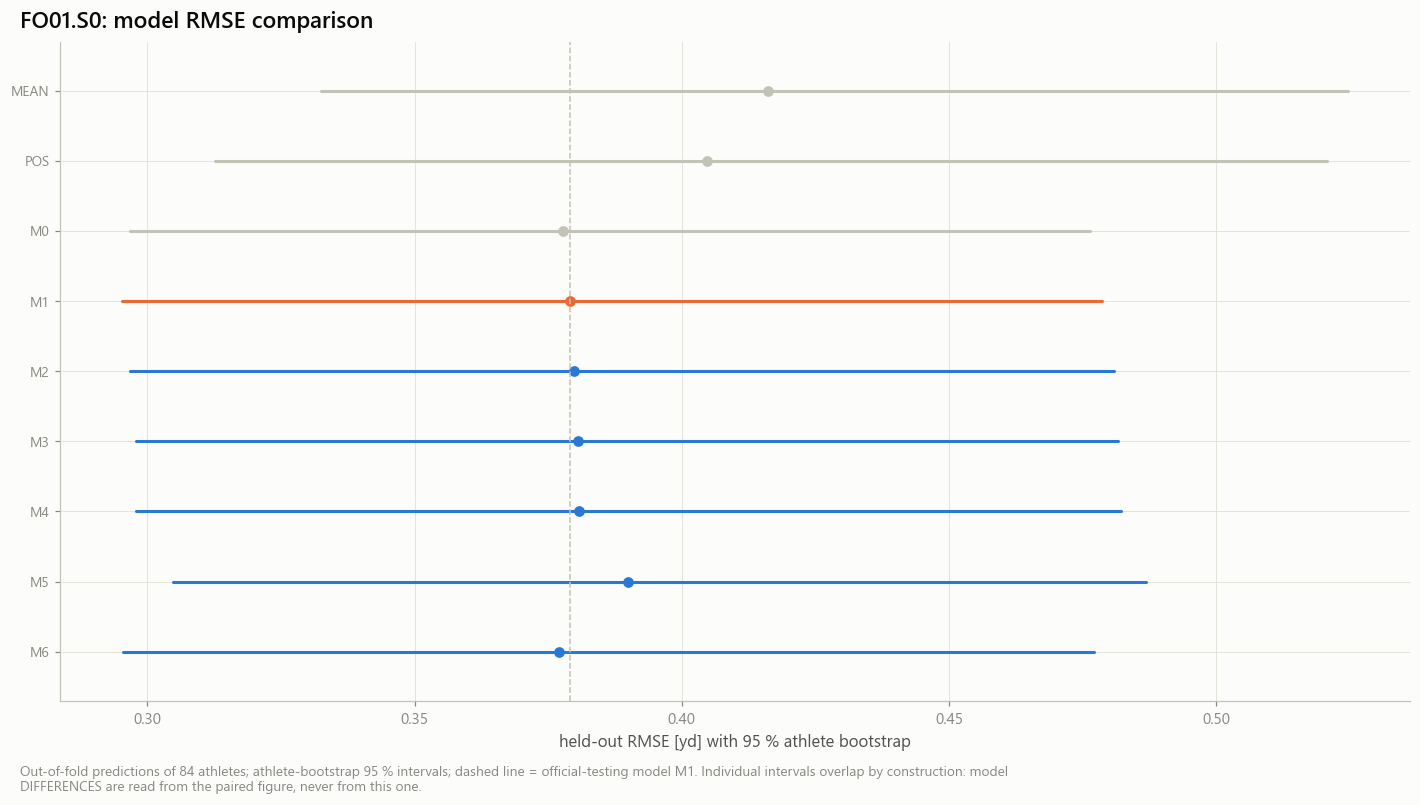

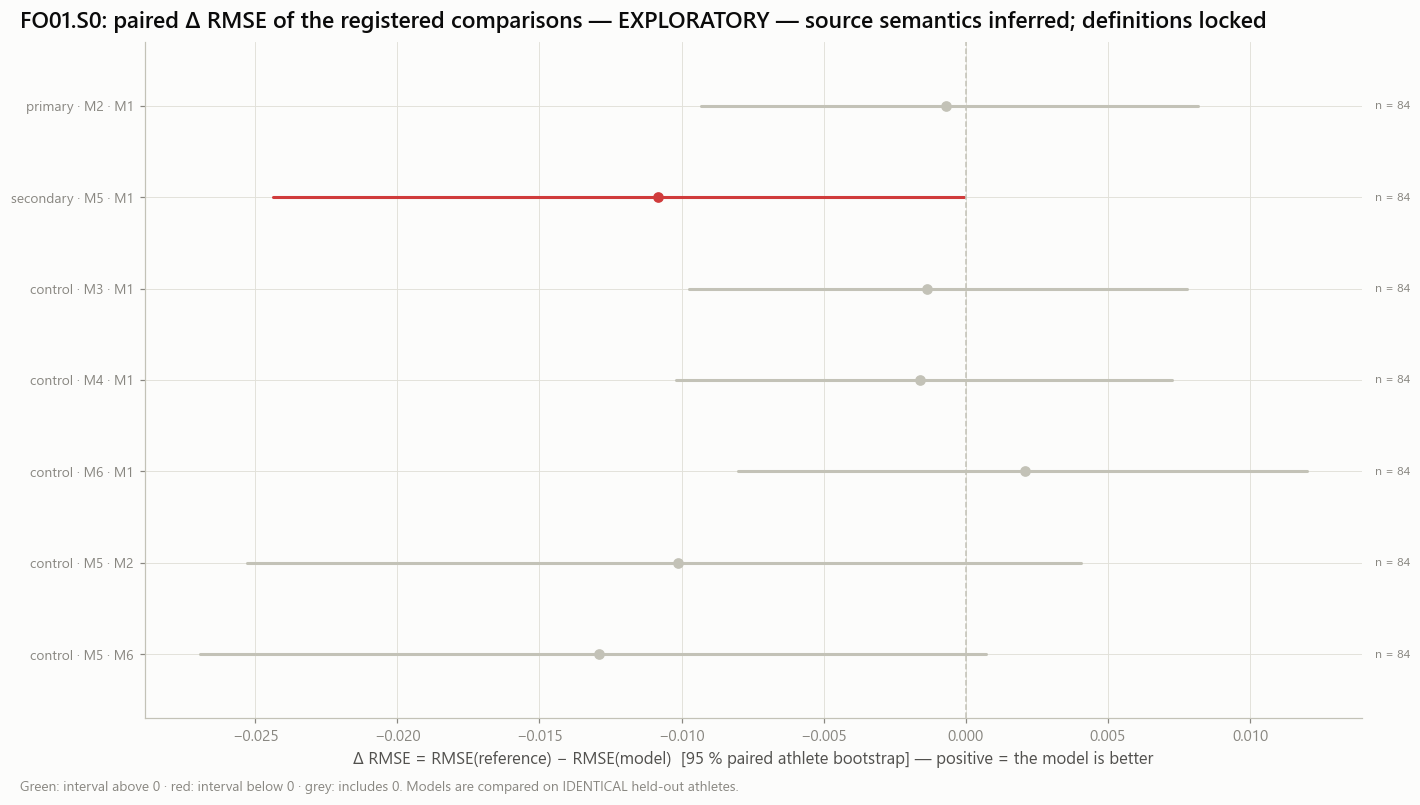

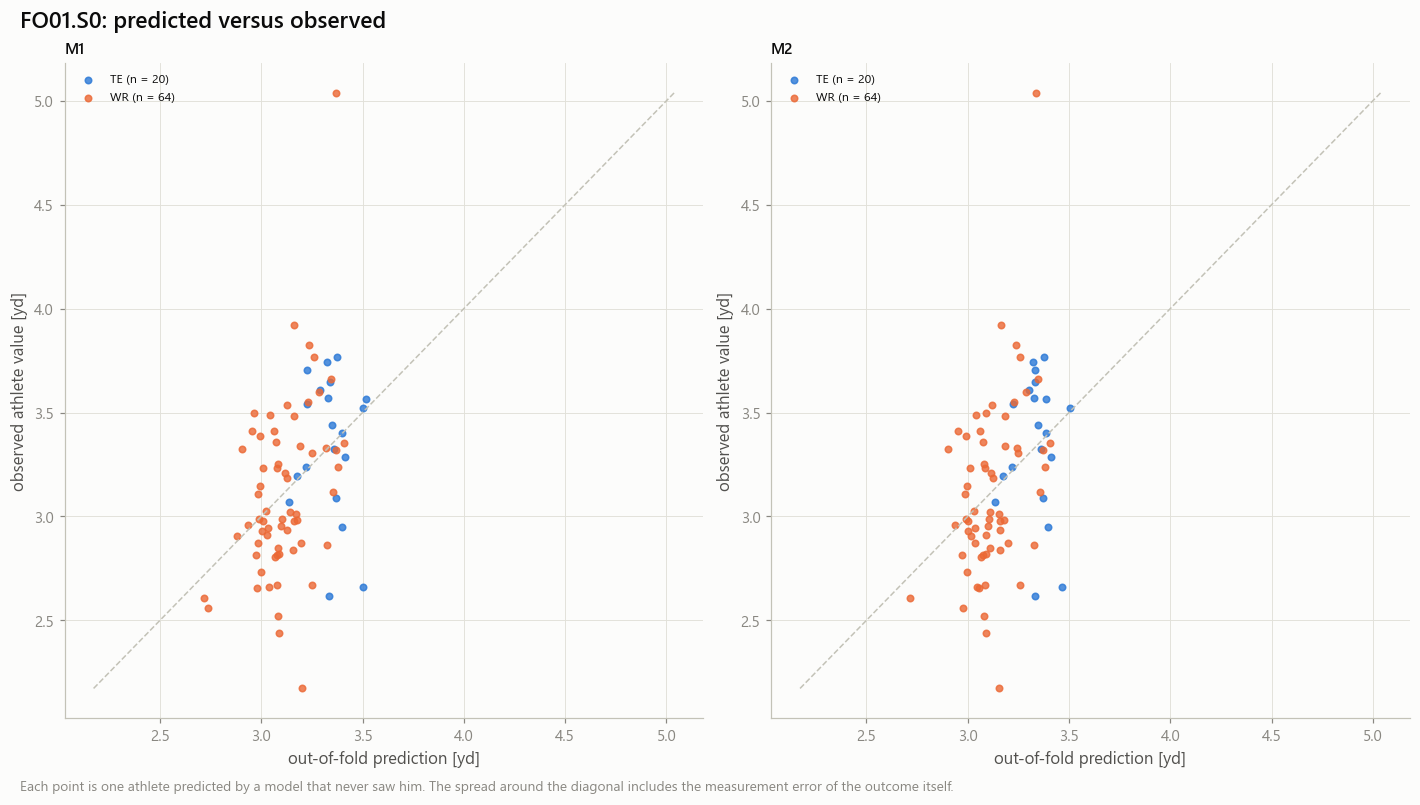

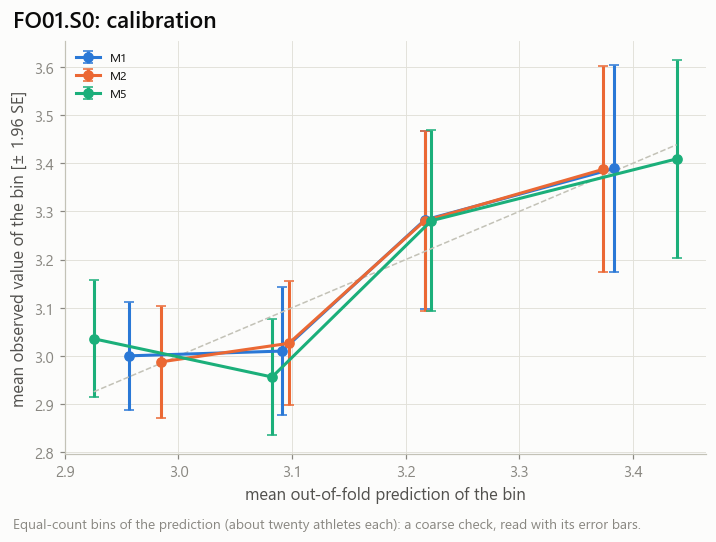

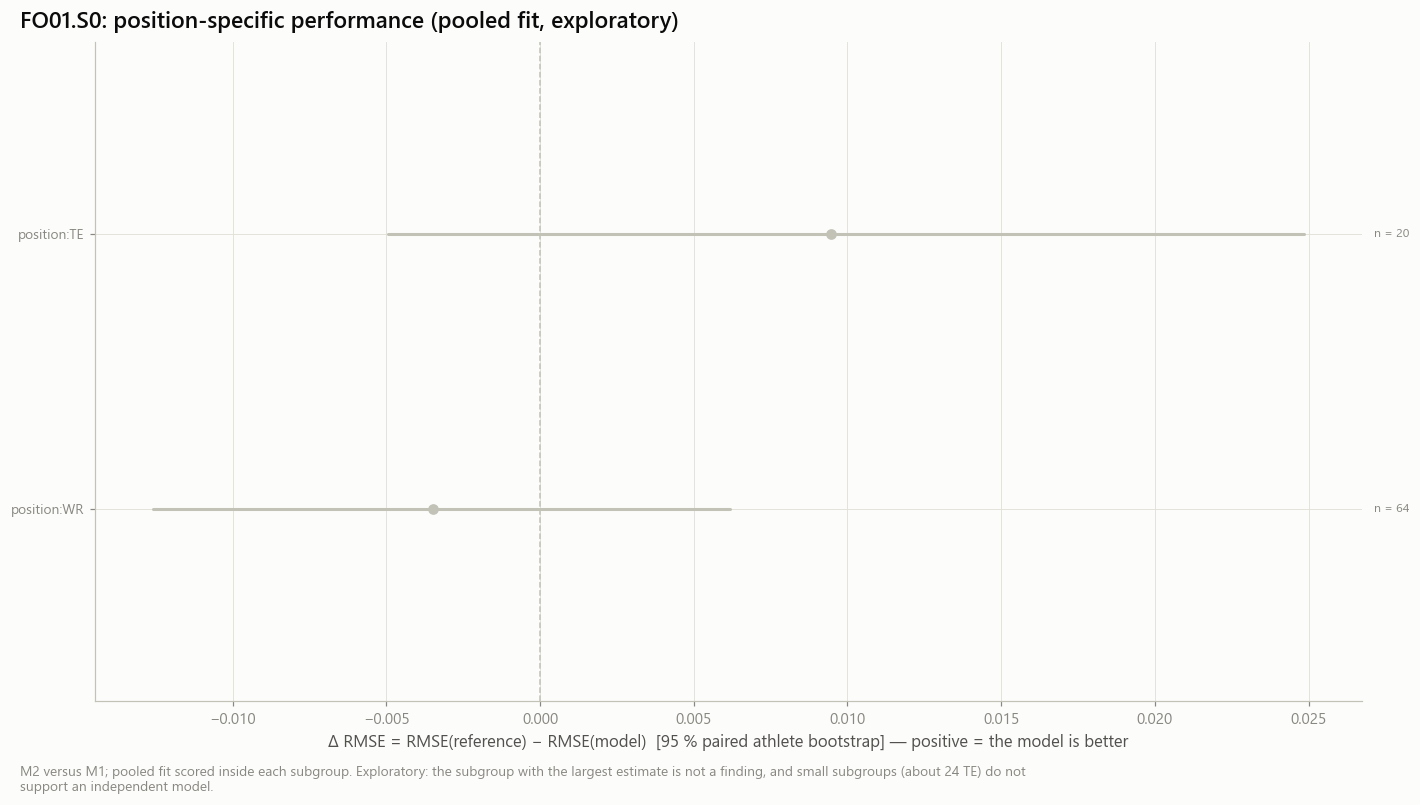

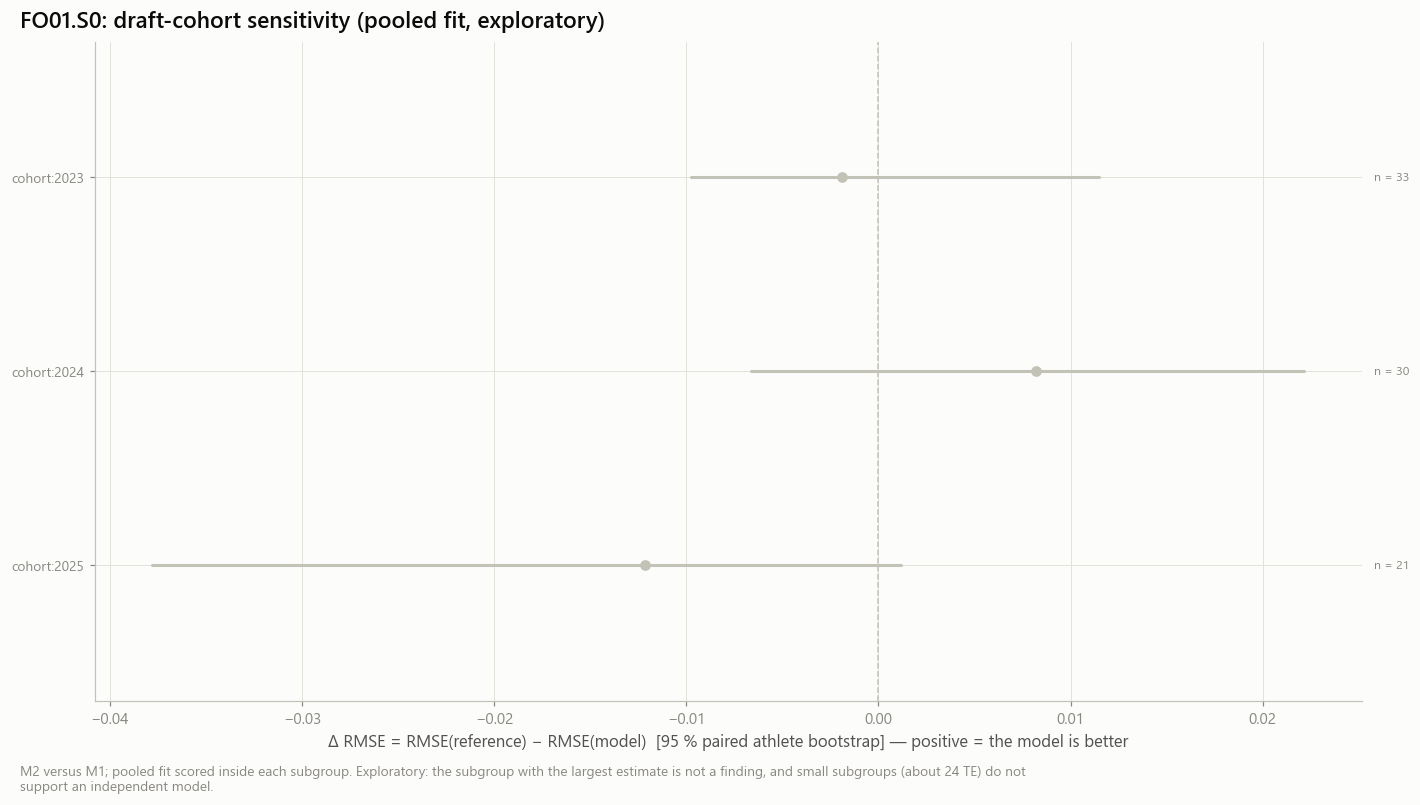

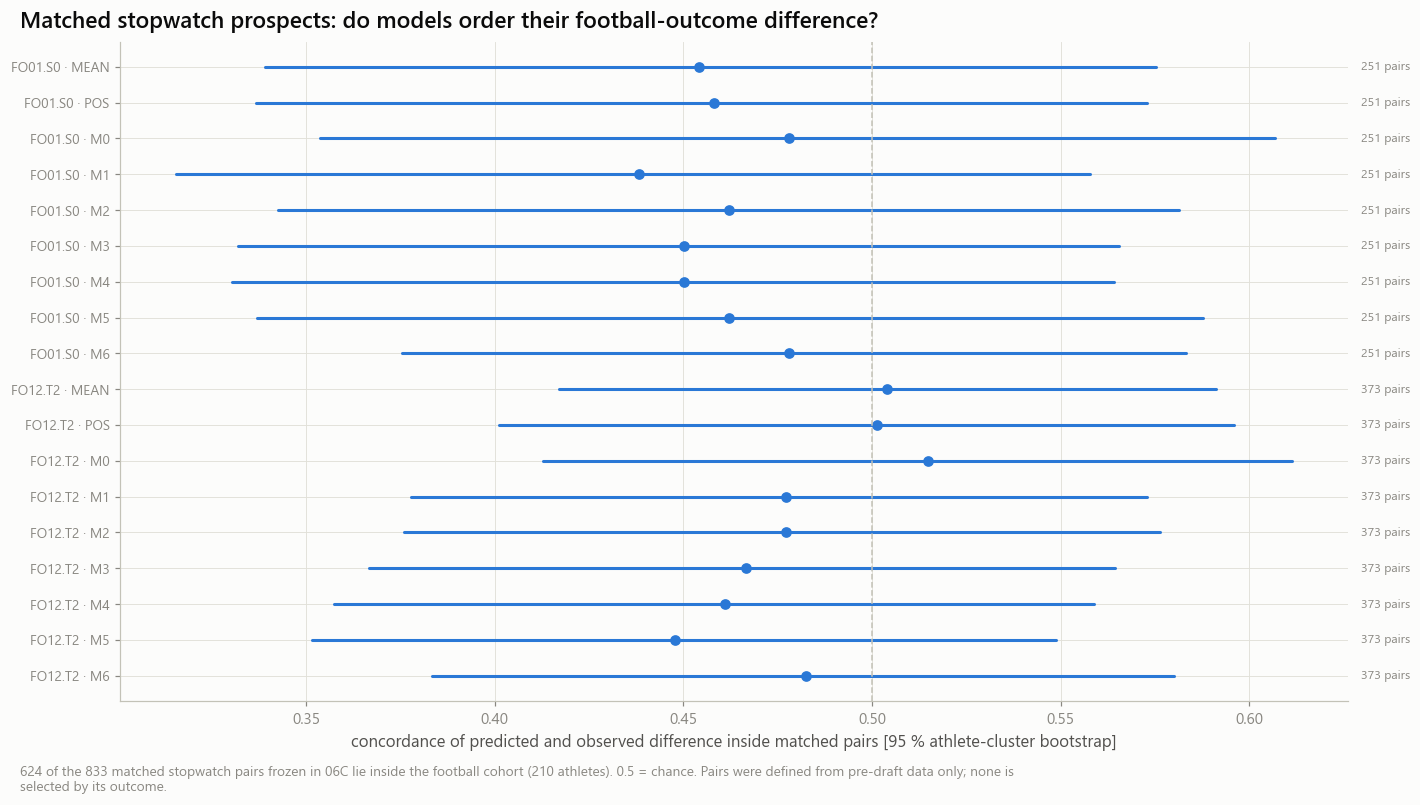

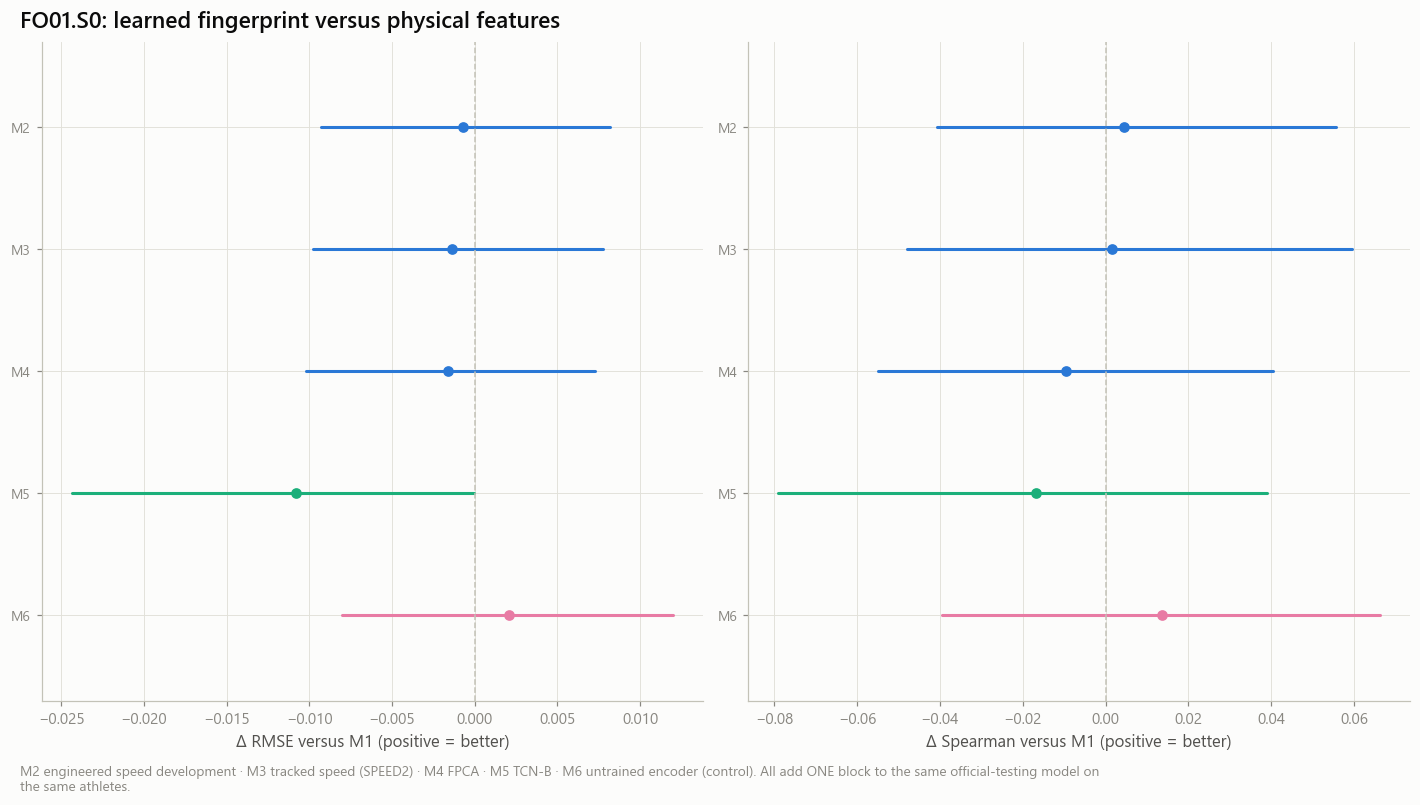

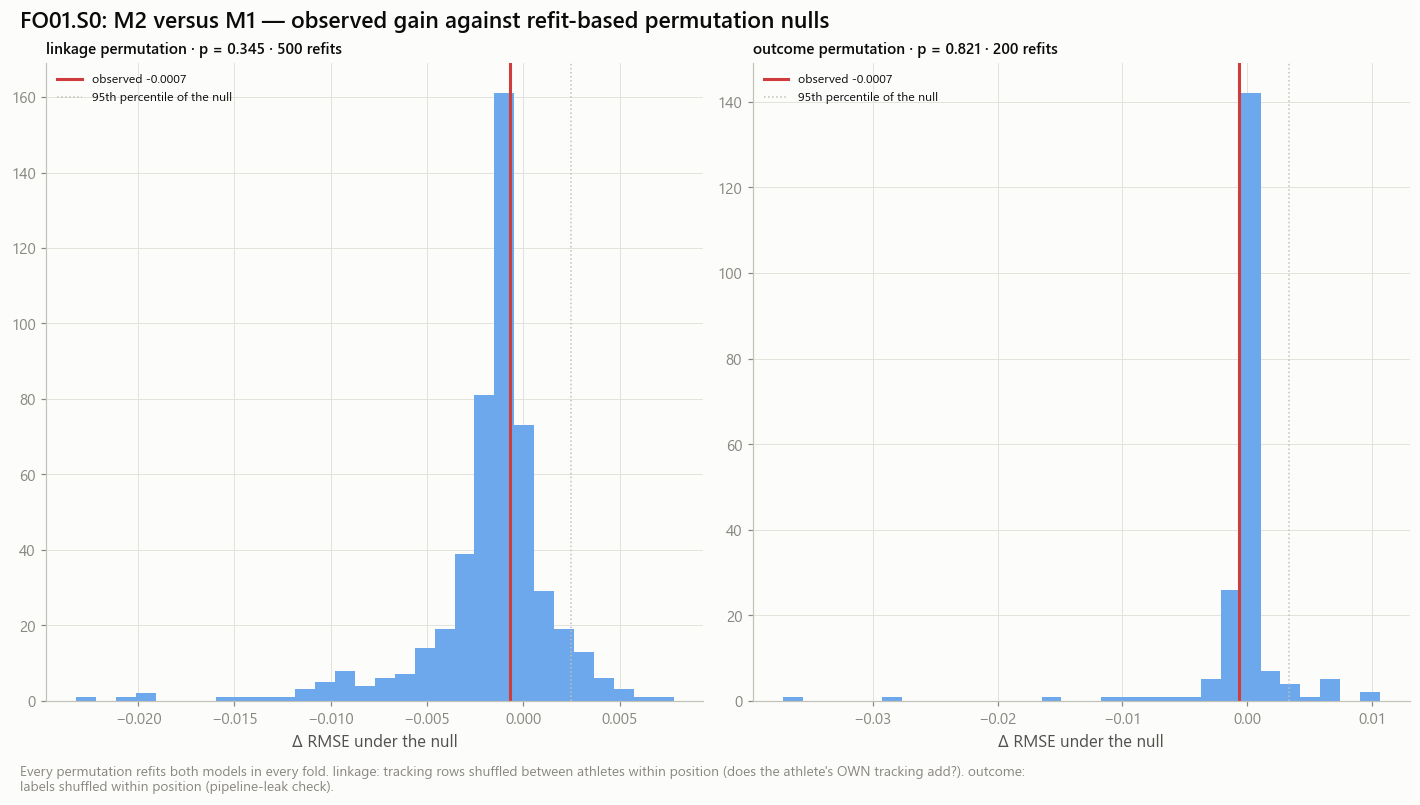

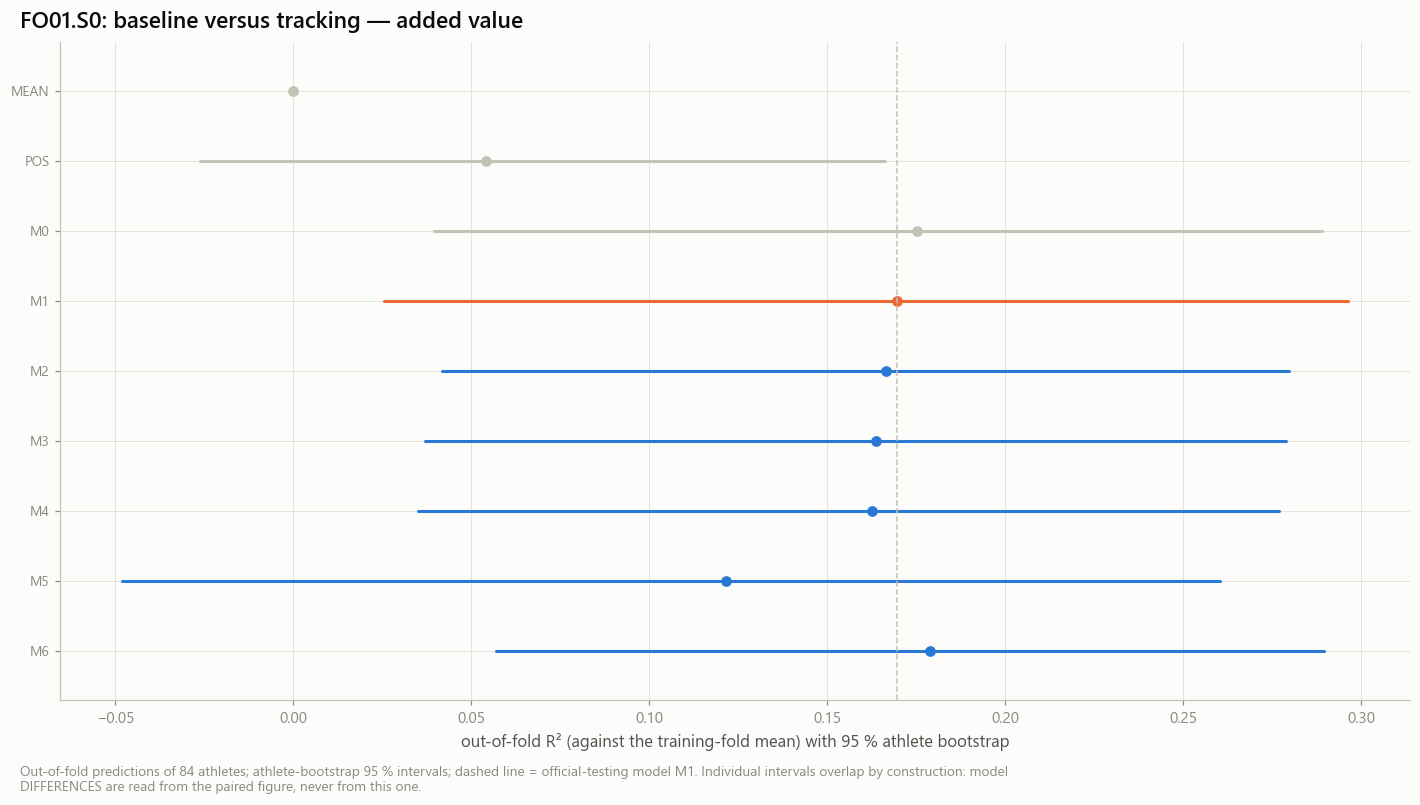

In [8]:
unit = fr.targets_of(REGISTRY, 'primary')[0]['units']
P0, P1 = HYP['primary']
src, n_txt = 'football_transfer_* tables', f'{N_PRIMARY} athletes ({POSITION_COUNTS})'
store.show(ff.fig_model_metric(perf, PRIMARY, 'rmse', f'held-out RMSE [{unit}] with 95 % athlete bootstrap', f'{PRIMARY}: model RMSE comparison', ftc.models),
           'AM08B2_01_model_rmse_comparison', {'performance': perf.filter(pl.col('target_id') == PRIMARY)}, publication=True, source=src, n=n_txt)
store.show(ff.fig_paired_forest(hyp_table.filter(pl.col('target_id') == PRIMARY), f'{PRIMARY}: paired Δ RMSE of the registered comparisons — {BRANCH["label"]}'),
           'AM08B2_02_paired_delta_rmse_forest', {'hypotheses': hyp_table}, publication=True, source=src, n=n_txt)
store.show(ff.fig_pred_vs_obs(oof, PRIMARY, ['M1', P0], unit), 'AM08B2_03_predicted_versus_observed', {}, source=src, n=n_txt)
store.show(ff.fig_calibration(calib, PRIMARY, ['M1', P0, 'M5']), 'AM08B2_04_calibration', {'calibration': calib}, source=src, n=n_txt)
store.show(ff.fig_subgroups(subgroup, PRIMARY, 'position', (P0, P1), f'{PRIMARY}: position-specific performance (pooled fit, exploratory)'),
           'AM08B2_05_position_specific_performance', {'subgroups': subgroup}, source=src, n=n_txt)
store.show(ff.fig_subgroups(subgroup, PRIMARY, 'cohort', (P0, P1), f'{PRIMARY}: draft-cohort sensitivity (pooled fit, exploratory)'),
           'AM08B2_06_cohort_sensitivity', {'subgroups': subgroup}, source=src, n=n_txt)
store.show(ff.fig_matched(matched, MATCH_COUNTS), 'AM08B2_07_matched_prospect_concordance', {'matched': matched}, publication=True, source=src,
           n=f'{MATCH_COUNTS["pairs_in_cohort"]} pairs, {MATCH_COUNTS["athletes_in_pairs"]} athletes')
store.show(ff.fig_tcn_vs_physical(paired, PRIMARY), 'AM08B2_08_tcn_versus_physical_features', {}, source=src, n=n_txt)
store.show(ff.fig_null(perm_draws, perm.filter((pl.col('model') == P0) & (pl.col('reference') == P1)), f'{PRIMARY}: {P0} versus {P1} — observed gain against refit-based permutation nulls'),
           'AM08B2_09_uncertainty_bootstrap_versus_permutation', {'permutation': perm}, publication=True, source=src, n=n_txt)
store.show(ff.fig_model_metric(perf, PRIMARY, 'r2_oos', 'out-of-fold R² (against the training-fold mean) with 95 % athlete bootstrap',
                               f'{PRIMARY}: baseline versus tracking — added value', ftc.models),
           'AM08B2_10_baseline_versus_tracking_added_value', {}, publication=True, source=src, n=n_txt)

## 6 · Gate C — is the experiment valid?

Gate C checks the **experiment**, not its sign: registry branch, Gate B, athlete-held-out predictions, one common cohort, viable folds, no NFL predictor, baselines, the registered primary comparison, paired uncertainty, a complete permutation run, an explicit evidence label. A valid experiment that shows no added value **passes**.

In [9]:
gate = save(ft.gate_c(oof, paired, hyp_table, perm, fold_support, HYP, design_columns['m1_numeric'], BRANCH, GATE_B, PRIMARY), ft.GATE_C)
GATE_C = 'PASS' if bool(gate['passed'].all()) else 'FAIL'
with pl.Config(fmt_str_lengths=200, tbl_rows=-1):
    display(gate)
text = ft.conclusions_markdown(hyp_table, perf, matched, MATCH_COUNTS, gate, BRANCH, ftc)
display(Markdown(text))
if controls.save_tables:
    (store.tables_dir / 'football_transfer_conclusions.md').write_text(text, encoding='utf-8')
    prim = hyp_table.filter((pl.col('target_id') == PRIMARY) & (pl.col('role') == 'primary'))
    store.write_json('football_transfer_manifest', {
        'experiment_version': EXPERIMENT_VERSION, 'finished_at': utc_now(), 'gate_c': GATE_C, 'registry_version': REGISTRY['version'],
        'registry_hash': REGISTRY['version_hash'], 'branch': BRANCH, 'primary': PRIMARY, 'evaluated_targets': list(LABELS), 'n_primary': N_PRIMARY,
        'position_counts': POSITION_COUNTS, 'label_kind': LABELS[PRIMARY].kind, 'folds_hash': audit['folds_hash'], 'hypotheses': HYP,
        'primary_result': prim.row(0, named=True) if prim.height else None, 'permutation': summaries, 'matched_counts': MATCH_COUNTS,
        'outcome_reliability': m1.get('reliability', {}).get(PRIMARY), 'provenance': PROV})
print('Gate C:', GATE_C)

21:56:15 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:08B2] football_gate_c_transfer: 11 rows → warehouse/gold/advanced_movement/football_v1/football_gate_c_transfer.parquet


criterion,passed,detail
str,bool,str
"""registry_branch_allows_transfer""",true,"""EXPLORATORY — source semantics inferred; definitions locked"""
"""gate_b_passed_for_primary""",true,"""FO01.S0: Gate B PASS"""
"""athlete_held_out_predictions""",true,"""one prediction per athlete and model: True; every athlete in one fold: True"""
"""paired_common_cohort""",true,"""9 models on 84 identical athletes"""
"""folds_viable""",true,"""every outer fold holds enough held-out athletes and ≥ 3 training athletes of each position"""
"""no_nfl_predictor""",true,"""9 baseline predictors, all pre-draft; representations are the fold-fitted 06B blocks"""
"""baselines_included""",true,"""M0 and M1 evaluated"""
"""primary_comparison_is_the_registered_one""",true,"""registered ['M2', 'M1']"""
"""paired_uncertainty_calculated""",true,"""95 % paired athlete bootstrap on the primary comparison"""


### 08B.2 — football transfer benchmark

Evidence label: **EXPLORATORY — source semantics inferred; definitions locked** — exploratory association only — never a confirmed predictive claim.
Gate C: **PASS** (a valid experiment, whatever the sign of the result).

| Target | Role | Model vs reference | n | Δ RMSE [95 %] | Relative | p linkage | p outcome | Holm | Reading |
|---|---|---|---|---|---|---|---|---|---|
| `FO01.S0` | primary | M2 vs M1 | 84 | -0.0007 [-0.0093, +0.0082] | -0.18 % | 0.345 | 0.821 | 0.691 | not established (interval includes 0) |
| `FO01.S0` | secondary | M5 vs M1 | 84 | -0.0108 [-0.0244, -0.0001] | -2.85 % | 0.886 | n/a | 0.886 | the tracking model is worse (interval below 0) |
| `FO01.S0` | control | M3 vs M1 | 84 | -0.0014 [-0.0098, +0.0078] | -0.36 % | n/a | n/a | n/a | not established (interval includes 0) |
| `FO01.S0` | control | M4 vs M1 | 84 | -0.0016 [-0.0102, +0.0073] | -0.43 % | n/a | n/a | n/a | not established (interval includes 0) |
| `FO01.S0` | control | M6 vs M1 | 84 | +0.0021 [-0.0080, +0.0120] | +0.55 % | n/a | n/a | n/a | not established (interval includes 0) |
| `FO01.S0` | control | M5 vs M2 | 84 | -0.0101 [-0.0253, +0.0041] | -2.67 % | n/a | n/a | n/a | not established (interval includes 0) |
| `FO01.S0` | control | M5 vs M6 | 84 | -0.0129 [-0.0269, +0.0007] | -3.42 % | n/a | n/a | n/a | not established (interval includes 0) |
| `FO12.T2` | primary | M2 vs M1 | 133 | +0.0001 [-0.0003, +0.0005] | +0.38 % | n/a | n/a | 0.640 | not established (interval includes 0) |
| `FO12.T2` | secondary | M5 vs M1 | 133 | +0.0003 [-0.0003, +0.0009] | +1.13 % | n/a | n/a | 0.598 | not established (interval includes 0) |
| `FO12.T2` | control | M3 vs M1 | 133 | +0.0001 [-0.0003, +0.0006] | +0.47 % | n/a | n/a | n/a | not established (interval includes 0) |
| `FO12.T2` | control | M4 vs M1 | 133 | +0.0001 [-0.0002, +0.0006] | +0.57 % | n/a | n/a | n/a | not established (interval includes 0) |
| `FO12.T2` | control | M6 vs M1 | 133 | +0.0002 [-0.0003, +0.0007] | +0.74 % | n/a | n/a | n/a | not established (interval includes 0) |
| `FO12.T2` | control | M5 vs M2 | 133 | +0.0002 [-0.0003, +0.0006] | +0.75 % | n/a | n/a | n/a | not established (interval includes 0) |
| `FO12.T2` | control | M5 vs M6 | 133 | +0.0001 [-0.0002, +0.0004] | +0.39 % | n/a | n/a | n/a | not established (interval includes 0) |

Baselines: `FO01.S0` M0 r2_oos 0.175; `FO01.S0` M0 rmse 0.378; `FO01.S0` M0 spearman 0.420; `FO01.S0` M1 r2_oos 0.170; `FO01.S0` M1 rmse 0.379; `FO01.S0` M1 spearman 0.421; `FO01.S0` POS r2_oos 0.054; `FO01.S0` POS rmse 0.405; `FO01.S0` POS spearman 0.135; `FO12.T2` M0 r2_oos 0.148; `FO12.T2` M0 rmse 0.026; `FO12.T2` M0 spearman 0.306; `FO12.T2` M1 r2_oos 0.137; `FO12.T2` M1 rmse 0.026; `FO12.T2` M1 spearman 0.340; `FO12.T2` POS r2_oos 0.167; `FO12.T2` POS rmse 0.025; `FO12.T2` POS spearman 0.305

Matched stopwatch prospects: 624 of 833 frozen 06C pairs lie inside the football cohort (210 athletes).
- `FO01.S0` M0: concordance 0.478 [0.354, 0.607], versus official +0.040 [-0.077, +0.159]
- `FO01.S0` M1: concordance 0.438 [0.316, 0.558], versus official n/a [n/a, n/a]
- `FO01.S0` M2: concordance 0.462 [0.342, 0.581], versus official +0.024 [-0.070, +0.125]
- `FO01.S0` M3: concordance 0.450 [0.332, 0.565], versus official +0.012 [-0.094, +0.112]
- `FO01.S0` M4: concordance 0.450 [0.330, 0.564], versus official +0.012 [-0.091, +0.113]
- `FO01.S0` M5: concordance 0.462 [0.337, 0.588], versus official +0.024 [-0.037, +0.086]
- `FO01.S0` M6: concordance 0.478 [0.376, 0.583], versus official +0.040 [-0.066, +0.137]
- `FO01.S0` MEAN: concordance 0.454 [0.339, 0.575], versus official +0.016 [-0.138, +0.185]
- `FO01.S0` POS: concordance 0.458 [0.337, 0.573], versus official +0.020 [-0.145, +0.188]
- `FO12.T2` M0: concordance 0.515 [0.413, 0.611], versus official +0.038 [-0.039, +0.121]
- `FO12.T2` M1: concordance 0.477 [0.378, 0.573], versus official n/a [n/a, n/a]
- `FO12.T2` M2: concordance 0.477 [0.376, 0.576], versus official +0.000 [-0.051, +0.053]
- `FO12.T2` M3: concordance 0.466 [0.367, 0.564], versus official -0.011 [-0.067, +0.041]
- `FO12.T2` M4: concordance 0.461 [0.357, 0.559], versus official -0.016 [-0.073, +0.036]
- `FO12.T2` M5: concordance 0.448 [0.352, 0.549], versus official -0.029 [-0.116, +0.049]
- `FO12.T2` M6: concordance 0.483 [0.383, 0.580], versus official +0.005 [-0.062, +0.076]
- `FO12.T2` MEAN: concordance 0.504 [0.417, 0.591], versus official +0.027 [-0.092, +0.143]
- `FO12.T2` POS: concordance 0.501 [0.401, 0.596], versus official +0.024 [-0.093, +0.138]

Limits: one linked cohort of about 90 receivers; an interaction outcome with inferred semantics; intervals cover athlete sampling, not model refitting; the practical margin (2%) is a heuristic; the linkage permutation also breaks the tracking–official link of the same athlete. Milestone 06 (no validated incremental prediction of NFL movement) is unchanged.

Gate C: PASS


## 7 · Reading

- The evidence label of the registry caps the wording: under an **exploratory** branch a positive result is an *exploratory association*, never a confirmed predictive claim.
- An interval that includes 0 means *not established in this cohort* — with about 90 athletes, small effects are not detectable (08B.3 quantifies what is).
- Whatever the result, the Milestone 06 conclusion (no validated incremental prediction of NFL movement) is unchanged: this is a new evidence family on a different outcome and a different cohort.

**Send back:** checks table, the cohort counts, the hypothesis table, the permutation table, `matched stopwatch pairs`, Gate C, figures `AM08B2_02`, `07`, `09`, `10`.

**Next:** `08b3_transfer_robustness_and_detectability.ipynb`.